# 08 · Traffic-adjusted hotspots: KSI risk per vehicle-km on major roads

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryam843/uk-road-accident-analytics/blob/main/notebooks/08_traffic_adjusted_hotspots.ipynb)

**Why:** notebook 05 found that 936 of the 1,002 Gi\* count hotspots are among the busiest 10% of
hexagons, and only 8 are also hot on KSI share. Counts mostly follow traffic. This notebook
divides KSI collisions by **traffic exposure** (vehicle-km from DfT traffic counts) to ask
where a journey is riskier, not just where collisions pile up.

**Data:** DfT road traffic statistics, annual average daily flow (AADF) by count point,
2015-2019 (OGL v3.0), and STATS19 collisions 2015-2019 on major roads.

**Steps**
1. Understand the traffic file; scope to major roads (where link lengths exist).
2. Match each major-road collision to the nearest count point on the same road, same year,
   within 2 km (5 km as a sensitivity check), using British National Grid metres.
3. KSI rate per 100 million vehicle-km per link with exact Poisson CIs, and empirical Bayes
   (Poisson-gamma) shrinkage within road group.
4. Gi\* (k = 6, 999 permutations, BH FDR 0.05) on EB KSI rates per H3 resolution-7 hexagon,
   compared with notebook 05's count hotspots on the same hexagons.

**Results (this run):** RESULTS_PLACEHOLDER

In [1]:
# Setup: works from the repo root, from notebooks/, or on Google Colab.
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src/config.py").exists():
    if not Path("uk-road-accident-analytics").exists():
        !git clone -q https://github.com/maryam843/uk-road-accident-analytics.git
    %cd uk-road-accident-analytics
    %pip install -q -r requirements.txt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import clean, config, evaluate

config.setup_logging(logging.INFO)
evaluate.apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

DATA_DIR = config.get_data_dir()
RAW, PROCESSED = DATA_DIR / "raw", DATA_DIR / "processed"
if not (PROCESSED / config.COLLISIONS_PARQUET).exists():
    # Fresh runtime (e.g. Colab): download (several GB) and clean. Takes a while, once.
    from src import download

    download.main([])
    clean.run()
print("DATA_DIR =", DATA_DIR)

import time

from src import traffic

YEARS = (2015, 2019)
GB_RES, K = 7, 6
PER = 1e8  # rates per 100 million vehicle-km
AADF_PATH = RAW / config.AADF_RAW_FILE
if not AADF_PATH.exists():
    from src import download

    download.main(["--only", "aadf", "aadf_metadata"])

DATA_DIR = data


## 1. Traffic data: what the AADF file contains

In [3]:
header = pd.read_csv(AADF_PATH, nrows=0).columns.tolist()
print(f"{len(header)} columns in the real file:", header)
aadf_raw = traffic.load_aadf(AADF_PATH, years=YEARS)
print(f"\nRows {YEARS[0]}-{YEARS[1]}: {len(aadf_raw):,} (one row per count point per year)")
display(aadf_raw.groupby(["year", "road_type"]).size().unstack().assign(total=lambda d: d.sum(axis=1)))
cats = (aadf_raw.groupby("road_category").agg(rows=("count_point_id", "size"),
                                               count_points=("count_point_id", "nunique"),
                                               share_with_link_length=("link_length_km", lambda s: s.notna().mean()))
        .assign(description=lambda d: d.index.map(traffic.ROAD_CATEGORIES)))
display(cats.style.format({"share_with_link_length": "{:.1%}"}))
print("Share of rows with link_length_km, by road type:",
      aadf_raw.groupby("road_type")["link_length_km"].apply(lambda s: round(s.notna().mean(), 4)).to_dict())
cp_len = aadf_raw.groupby(["road_type", "count_point_id"])["link_length_km"].apply(lambda s: s.notna().any())
print("Share of count points with a link_length_km (any year), by road type:",
      cp_len.groupby(level=0).mean().round(4).to_dict(), "| count points:", cp_len.groupby(level=0).size().to_dict())
mix = pd.crosstab(aadf_raw["road_type"], aadf_raw["estimation_method"], normalize="index")
print("Estimation method by road type (share of rows):")
display(mix.style.format("{:.1%}"))
print("Detailed method, major roads:",
      aadf_raw.loc[aadf_raw["road_type"] == "Major", "estimation_method_detailed"].value_counts(normalize=True)
      .round(3).to_dict())
print("Road names that are not plain M<n> / A<n> / A<n>(M) (major roads):",
      traffic.describe_road_names(aadf_raw.loc[aadf_raw["road_type"] == "Major", "road_name"]))

34 columns in the real file: ['count_point_id', 'year', 'region_id', 'region_name', 'region_ons_code', 'local_authority_id', 'local_authority_name', 'local_authority_code', 'road_name', 'road_category', 'road_type', 'start_junction_road_name', 'end_junction_road_name', 'easting', 'northing', 'latitude', 'longitude', 'link_length_km', 'link_length_miles', 'estimation_method', 'estimation_method_detailed', 'pedal_cycles', 'two_wheeled_motor_vehicles', 'cars_and_taxis', 'buses_and_coaches', 'LGVs', 'HGVs_2_rigid_axle', 'HGVs_3_rigid_axle', 'HGVs_4_or_more_rigid_axle', 'HGVs_3_or_4_articulated_axle', 'HGVs_5_articulated_axle', 'HGVs_6_articulated_axle', 'all_HGVs', 'all_motor_vehicles']



Rows 2015-2019: 128,836 (one row per count point per year)


road_type,Major,Minor,total
year,,,
2015,18050,4704,22754
2016,18083,4703,22786
2017,18154,4696,22850
2018,18193,9350,27543
2019,18197,14706,32903


,rows,count_points,share_with_link_length,description
road_category,,,,
MB,7391,2318,0.0%,"Minor road, class B"
MCU,30768,12603,0.0%,"Minor road, class C or unclassified"
PA,73924,15496,100.0%,Principal A road
PM,188,43,100.0%,Principal motorway
TA,10715,2379,100.0%,Trunk A road
TM,5850,1253,100.0%,Trunk motorway


Share of rows with link_length_km, by road type: {'Major': 1.0, 'Minor': 0.0}


Share of count points with a link_length_km (any year), by road type: {'Major': 1.0, 'Minor': 0.0} | count points: {'Major': 19158, 'Minor': 14904}
Estimation method by road type (share of rows):


estimation_method,Counted,Estimated
road_type,,
Major,22.3%,77.7%
Minor,82.0%,18.0%


Detailed method, major roads: {'Estimated using AADF from previous year on this link': 0.715, 'Manual count': 0.168, 'Estimated from nearby links': 0.062, 'Automatic counter': 0.035, 'Dependent on a neighbouring counted link': 0.017, 'Dependent on an automatic counter on a neighbouring link': 0.003}
Road names that are not plain M<n> / A<n> / A<n>(M) (major roads): {'M6(T)': 156, 'A57M': 30, 'A167M': 30, 'A38M': 20, 'A329M': 17, 'A74M': 17, 'A64M': 15, 'A58M': 15, 'A601M': 10, 'A194M': 6}


**Scope: major roads only.** Link lengths, and therefore vehicle-km, exist only for major roads
(motorways and A roads): every major-road row has a `link_length_km` and no minor-road row
does (shares printed above). Minor-road count points are a sample used by DfT for regional
estimates and do not describe a road link. So everything below is about **major roads**.
Most major-road AADFs are *estimated* from earlier counts on the same link rather than counted
in that year (mix above), so a link's flow is an estimate, not a measurement. DfT's metadata
also warns that AADFs at different count points should not be added together; vehicle-km
(AADF x link length x 365) is the quantity that can be summed.

In [4]:
aadf = traffic.clean_aadf(aadf_raw)
major = aadf[aadf["is_major"]]
print(f"Major-road rows: {len(major):,}; usable for exposure (coordinates, link length > 0, AADF >= 0): "
      f"{int(major['usable'].sum()):,}")
points = major[major["usable"]].assign(road_name=lambda d: d["road_name_norm"])
years_per_point = points.groupby("count_point_id")["year"].nunique()
print(f"Major-road count points: {len(years_per_point):,}; with AADF in all 5 years: "
      f"{int((years_per_point == 5).sum()):,}")
moved = points.groupby("count_point_id")[["easting", "northing"]].nunique().max(axis=1) > 1
relength = points.groupby("count_point_id")["link_length_km"].nunique() > 1
print(f"Count points whose location changes between years: {int(moved.sum()):,}; whose link length changes: "
      f"{int(relength.sum()):,}. So collisions are matched per year (step 2).")
vkm_year = points.pivot_table(index="year", columns="road_group", values="vehicle_km", aggfunc="sum") / 1e9
vkm_year["all major roads"] = vkm_year.sum(axis=1)
print("Vehicle-km per year (billions) = AADF all_motor_vehicles x link_length_km x 365:")
display(vkm_year.style.format("{:,.1f}"))

Major-road rows: 90,677; usable for exposure (coordinates, link length > 0, AADF >= 0): 90,677
Major-road count points: 19,158; with AADF in all 5 years: 17,139
Count points whose location changes between years: 2,339; whose link length changes: 3,851. So collisions are matched per year (step 2).
Vehicle-km per year (billions) = AADF all_motor_vehicles x link_length_km x 365:


road_group,Motorway,Principal A road,Trunk A road,all major roads
year,,,,
2015,107.0,160.6,66.3,333.9
2016,108.6,163.3,69.1,341.1
2017,110.4,164.1,71.6,346.1
2018,111.1,166.2,72.8,350.2
2019,113.5,167.4,74.3,355.2


## 2. Matching collisions to traffic links

Major-road collisions 2015-2019 are those whose `first_road_class` is Motorway, A(M) or A and
whose coordinates are valid. Their road name is built from class and `first_road_number`
(`M25`, `A1`, `A1(M)`), the same format as the cleaned AADF names. Each collision is assigned to
the nearest count point **on the same road, with an AADF in the same year**, using British
National Grid easting/northing (metres). The primary distance cap is 2 km; 5 km is a
sensitivity check.

In [5]:
CC = ["collision_index", "collision_year", "first_road_class", "first_road_class_label", "first_road_number",
      "location_easting_osgr", "location_northing_osgr", "coord_valid", "ksi", "latitude", "longitude",
      "junction_detail_historic_label"]
coll = pd.read_parquet(PROCESSED / config.COLLISIONS_PARQUET, columns=CC)
coll = coll[coll["collision_year"].between(*YEARS)]
is_major = coll["first_road_class"].isin(list(traffic.STATS19_MAJOR_CLASSES))
print(f"Collisions {YEARS[0]}-{YEARS[1]}: {len(coll):,}; on major roads: {int(is_major.sum()):,}")
mc = coll[is_major & coll["coord_valid"]].copy()
no_grid = mc["location_easting_osgr"].isna() | mc["location_northing_osgr"].isna()
print(f"With valid coordinates: {len(mc):,}; of which without a grid reference (excluded): {int(no_grid.sum()):,}")
mc = mc[~no_grid]
mc["road_name"] = traffic.collision_road_name(mc["first_road_class"], mc["first_road_number"])
mc["ksi"] = mc["ksi"].astype(int)
print("By road class:", mc["first_road_class_label"].value_counts().loc[lambda v: v > 0].to_dict())
print("Most common road names:", mc["road_name"].value_counts().head(8).to_dict())
print(f"Road name also present among usable AADF count points: {mc['road_name'].isin(set(points['road_name'])).mean():.2%}")

Collisions 2015-2019: 646,830; on major roads: 312,466
With valid coordinates: 312,386; of which without a grid reference (excluded): 0


By road class: {'A': 287961, 'Motorway': 22616, 'A(M)': 1809}
Most common road names: {'A38': 3419, 'A4': 3392, 'A23': 3294, 'M25': 3267, 'A1': 3258, 'A5': 2922, 'A3': 2922, 'A40': 2894}
Road name also present among usable AADF count points: 99.88%


Matching at two caps took 34 s


,2 km cap,5 km cap
reason,,
matched,"276,079","304,857"
missing road number,0,0
no same-road count point,521,521
beyond distance cap,"35,786","7,008"
total,"312,386","312,386"


Share of major-road collisions matched: {'2 km cap': '88.4%', '5 km cap': '97.6%'}
Distance to the nearest same-road count point (all collisions with one): median 460 m, p90 2,206 m, p99 7,055 m
Share matched at 2 km by road class: {'A': 0.893, 'A(M)': 0.753, 'Motorway': 0.773}
KSI share: matched 0.1727, unmatched 0.2437


18:46:58 INFO src.evaluate: Saved figure reports/figures/08_match_distance.png


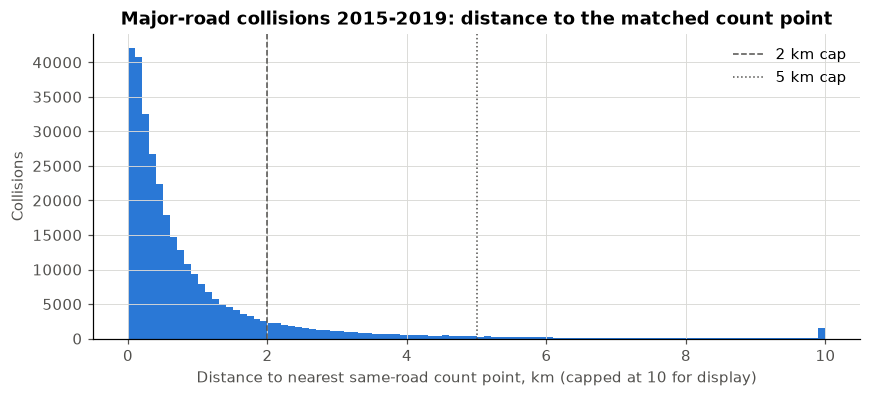

In [6]:
def match(cap_m):
    query = pd.DataFrame({"road_name": mc["road_name"], "easting": mc["location_easting_osgr"].astype(float),
                          "northing": mc["location_northing_osgr"].astype(float),
                          "year": mc["collision_year"].astype(int)}, index=mc.index)
    return traffic.match_to_count_points(query, points, cap_m=cap_m)


t0 = time.time()
m2, m5 = match(2_000), match(5_000)
print(f"Matching at two caps took {time.time() - t0:.0f} s")
summary = pd.DataFrame({"2 km cap": m2["reason"].value_counts(), "5 km cap": m5["reason"].value_counts()}).fillna(0)
summary = summary.reindex(["matched", *traffic.UNMATCHED_REASONS], fill_value=0).astype(int)
summary.loc["total"] = summary.sum()
share = (summary.loc["matched"] / len(mc)).rename("share matched")
display(summary.style.format("{:,}"))
print("Share of major-road collisions matched:", {k: f"{v:.1%}" for k, v in share.items()})
d = m2["distance_m"].dropna()
print(f"Distance to the nearest same-road count point (all collisions with one): median {d.median():,.0f} m, "
      f"p90 {d.quantile(0.9):,.0f} m, p99 {d.quantile(0.99):,.0f} m")
mc["count_point_id"], mc["distance_m"], mc["reason"] = m2["count_point_id"], m2["distance_m"], m2["reason"]
mc["count_point_id_5km"] = m5["count_point_id"]
by_class = mc.groupby("first_road_class_label", observed=True)["reason"].apply(lambda s: (s == "matched").mean())
print("Share matched at 2 km by road class:", by_class.round(3).to_dict())
print(f"KSI share: matched {mc.loc[mc['reason'] == 'matched', 'ksi'].mean():.4f}, "
      f"unmatched {mc.loc[mc['reason'] != 'matched', 'ksi'].mean():.4f}")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(np.minimum(d, 10_000) / 1000, bins=100, color=evaluate.PALETTE[0])
for cap, ls in [(2, "--"), (5, ":")]:
    ax.axvline(cap, color="#52514e", linestyle=ls, linewidth=1, label=f"{cap} km cap")
ax.set_xlabel("Distance to nearest same-road count point, km (capped at 10 for display)")
ax.set_ylabel("Collisions")
ax.set_title("Major-road collisions 2015-2019: distance to the matched count point")
ax.legend()
evaluate.save_fig(fig, "08_match_distance")
plt.show()